<a href="https://colab.research.google.com/github/harshhlf2024-cmyk/minor-1/blob/main/minor_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#import Libraries
import pandas as pd # data manipulation / analysis
import numpy as np # mathematical operation
import matplotlib.pyplot as plt # visualization
import seaborn as sns # visualization

In [2]:
# loading dataset
from google.colab import files
uploaded = files.upload()
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file)

Saving CAR DETAILS FROM CAR DEKHO.csv to CAR DETAILS FROM CAR DEKHO.csv


In [3]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [4]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [6]:
df.duplicated().sum()

np.int64(763)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.isnull().sum()

,0
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0


In [12]:
#outliers
df.select_dtypes(include = ['int64', 'float64']).columns

Index(['year', 'selling_price', 'km_driven'], dtype='object')

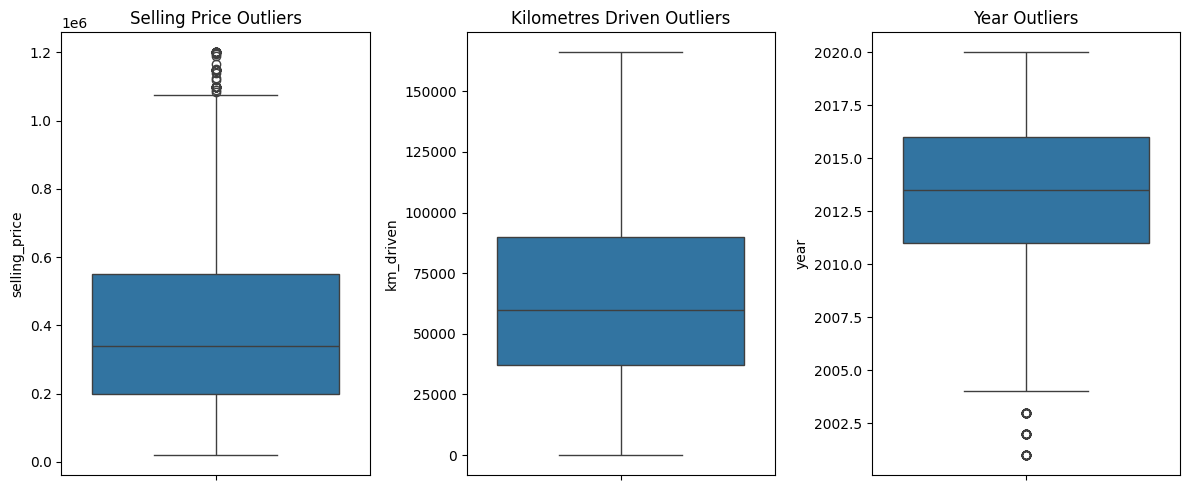

In [18]:
original_df = df.copy()

# Before removing outliers
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
sns.boxplot(y=original_df['selling_price'])
plt.title("Selling Price Outliers")

plt.subplot(1, 3, 2)
sns.boxplot(y=original_df['km_driven'])
plt.title("Kilometres Driven Outliers")

plt.subplot(1, 3, 3)
sns.boxplot(y=original_df['year'])
plt.title("Year Outliers")

plt.tight_layout()
plt.show()

In [14]:
cols = ['selling_price', 'km_driven','year' ]

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print(df.shape)

(3250, 8)


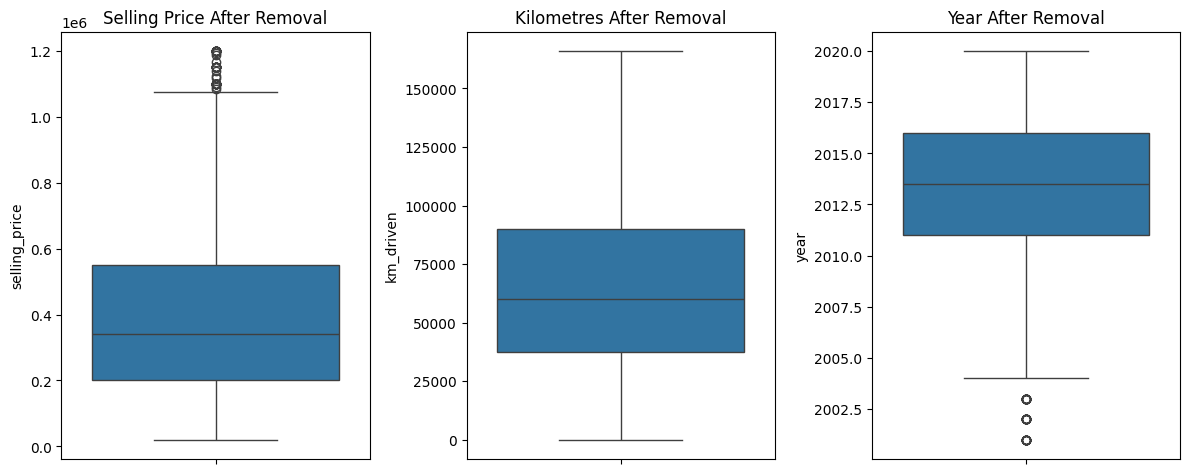

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
sns.boxplot(y=df['selling_price'])
plt.title("Selling Price After Removal")

plt.subplot(1, 3, 2)
sns.boxplot(y=df['km_driven'])
plt.title("Kilometres After Removal")

plt.subplot(1, 3, 3)
sns.boxplot(y=df['year'])
plt.title("Year After Removal")

plt.tight_layout()
plt.show()

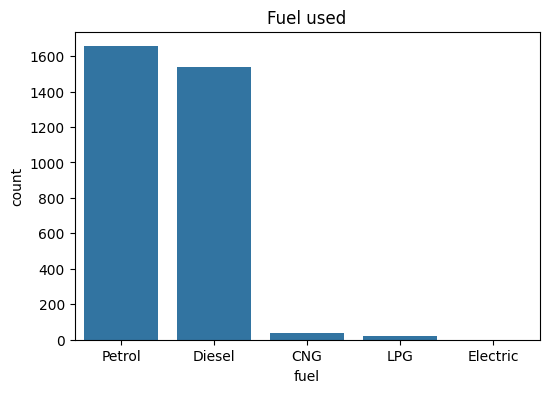

In [21]:
#univarient analysis
plt.figure(figsize= (6,4))
sns.countplot(x = df['fuel'])
plt.title("Fuel used")
plt.show()

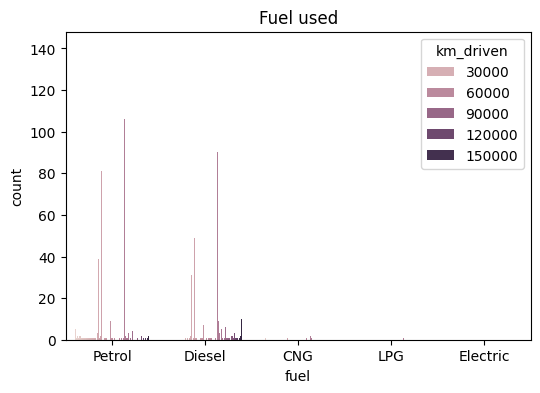

In [22]:
# Bivariate analysis
plt.figure(figsize= (6,4))
sns.countplot(x = df['fuel'], hue = df['km_driven'])
plt.title("Fuel used")
plt.show()



In [23]:
#multivariate analysis
sns.catplot(x = 'fuel',hue = 'km_driven', col = 'year', data = df, kind = 'count')
plt.show()

In [24]:
# converting objective data to numerical

df1= df.select_dtypes(include = 'object').columns
df1

Index(['name', 'fuel', 'seller_type', 'transmission', 'owner'], dtype='object')

In [25]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df1:

  df[col] = le.fit_transform(df[col])

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3250 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   name           3250 non-null   int64
 1   year           3250 non-null   int64
 2   selling_price  3250 non-null   int64
 3   km_driven      3250 non-null   int64
 4   fuel           3250 non-null   int64
 5   seller_type    3250 non-null   int64
 6   transmission   3250 non-null   int64
 7   owner          3250 non-null   int64
dtypes: int64(8)
memory usage: 357.6 KB
